In [1]:
# # UniGuide Courses - end-to-end run
# Runs the whole final protocol with the hyperparameters of `config.yaml`:
# data -> splits -> models -> main comparison (accuracy + beyond accuracy) -> cold-start -> ablation / sparsity.
# Hyperparameter tuning lives in notebooks 03-06 (their results are copied into `config.yaml`).
# Run all cells from the repository root environment (`pip install -e .`).

# %%
REBUILD_DATA = False    # True: rebuild interactions + splits from the raw Kaggle CSV files (data/raw/)
RUN_EXTENDED = True     # False: skip the slowest experiments (sparsity, ablation)

# %%
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uniguide.config import get_path, load_config
from uniguide.data.stats import save_fig
from uniguide.evaluation.beyond_accuracy import (
    ItemSimilarity, evaluate_beyond_accuracy, evaluation_users, popularity_from_train)
from uniguide.evaluation.experiments import (
    across_seeds, ablation_models, cold_course_experiment, cold_user_experiment,
    evaluate_models, sparsity_experiment, summarize)
from uniguide.pipeline import build_hybrid, model_factories

cfg = load_config()
SEED = cfg["seed"]
K_VALUES = tuple(cfg["evaluation"]["k_values"])
SEEDS = [SEED + i for i in range(cfg["evaluation"]["n_seeds"])]
p = get_path("processed")
tables = get_path("results") / "tables"
tables.mkdir(parents=True, exist_ok=True)

In [2]:
# ## 1. Data and splits

# %%
if REBUILD_DATA:
    from uniguide.data.build import build_interactions
    from uniguide.data.splits import make_splits
    build_interactions()
    make_splits()

train, val, test = (pd.read_parquet(p / f"{n}.parquet") for n in ["train", "val", "test"])
cold_course_test = pd.read_parquet(p / "cold_course_test.parquet")
courses = pd.read_parquet(p / "courses.parquet")
cold_courses = sorted(json.loads((p / "cold_courses.json").read_text()))
courses_warm = courses[~courses["course_id"].isin(cold_courses)].reset_index(drop=True)
cold_users = json.loads((p / "cold_users.json").read_text())
train_val = pd.concat([train, val], ignore_index=True)

n_users, n_courses = train_val["user_id"].nunique(), train_val["course_id"].nunique()
print(f"users {n_users:,} | courses {n_courses:,} | train+val interactions {len(train_val):,} | "
      f"sparsity {1 - len(train_val) / (n_users * n_courses):.4f}")
pd.read_csv(tables / "splits_summary.csv")


users 14,756 | courses 380 | train+val interactions 98,513 | sparsity 0.9824


,set,n_rows,n_users,n_courses
0,train,81530,14756,380
1,val,16983,14756,378
2,test,24629,14756,380
3,cold_course_test,15434,9514,42


In [3]:
# ## 2. Fit all methods (train + validation only)

# %%
factories = model_factories()
models = {name: factory().fit(train_val, courses_warm) for name, factory in factories.items()}
models["hybrid_rrf"] = build_hybrid(rrf=True).fit(train_val, courses_warm)
print({k: type(v).__name__ for k, v in models.items()})


{'popularity': 'PopularityRecommender', 'content_based': 'ContentBasedRecommender', 'collaborative': 'CollaborativeRecommender', 'hybrid': 'HybridRecommender', 'hybrid_rrf': 'RRFHybridRecommender'}


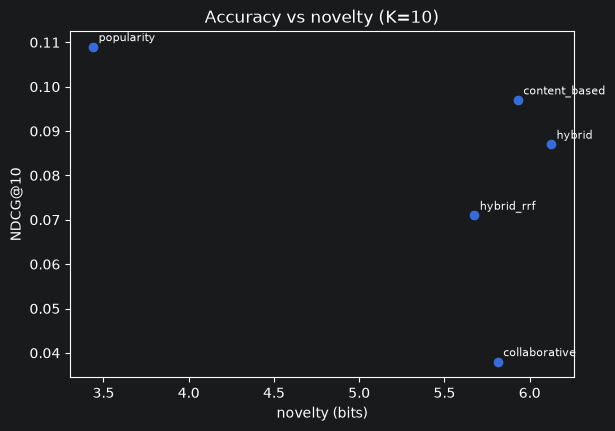

In [4]:
# ## 3. Main comparison: accuracy and beyond accuracy (same users, same K)

# %%
per_user = evaluate_models(models, test, K_VALUES, experiment="main", seed=SEED, per_user=True)
for name in models:
    per_user[per_user["method"] == name].to_csv(tables / f"eval_{name}.csv", index=False)
accuracy = summarize(per_user)

users = evaluation_users(test)
catalog = courses_warm["course_id"].tolist()
similarity = ItemSimilarity.from_content_model(models["content_based"])
popularity = popularity_from_train(train_val, catalog)
beyond = pd.concat([
    evaluate_beyond_accuracy(model, users, similarity, popularity, set(catalog), K_VALUES, "main", SEED)
    for model in models.values()
])
beyond.to_csv(tables / "eval_beyond_accuracy.csv", index=False)

acc_k = accuracy.pivot_table(index=["method", "k"], columns="metric", values="mean")
bey_k = beyond.groupby(["method", "k", "metric"])["value"].mean().unstack("metric")
comparison = acc_k.join(bey_k, how="outer").xs(10, level="k")
cols = [c for c in ["ndcg", "hit_rate", "precision", "recall", "coverage", "diversity", "novelty"]
        if c in comparison.columns]
comparison = comparison[cols].round(3)
comparison.to_csv(tables / "comparison_k10.csv")
comparison

# %%
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(comparison["novelty"], comparison["ndcg"])
for method, row in comparison.iterrows():
    ax.annotate(method, (row["novelty"], row["ndcg"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="novelty (bits)", ylabel="NDCG@10", title="Accuracy vs novelty (K=10)")
save_fig(fig, "accuracy_vs_novelty")

metric,hit_rate,ndcg,precision,recall
method,,,,
collaborative,0.0000,0.0000,0.0000,0.0000
content_based,0.6457,0.3691,0.0787,0.5291
hybrid,0.6457,0.3691,0.0787,0.5291
popularity,0.0000,0.0000,0.0000,0.0000


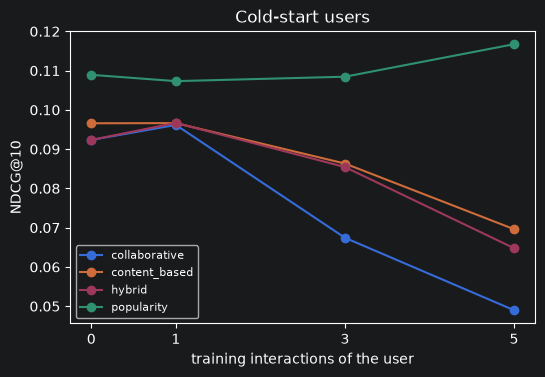

In [5]:
# ## 4. Cold-start users and cold-start courses

# %%
cold_u = cold_user_experiment(factories, train_val, test, courses_warm, cold_users, K_VALUES, seed=SEED)
cold_u["history"] = cold_u["experiment"].str.replace("cold_users_", "").astype(int)
cold_u.to_csv(tables / "exp_cold_users.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 3.8))
for method, g in cold_u[(cold_u["k"] == 10) & (cold_u["metric"] == "ndcg")].groupby("method"):
    g = g.sort_values("history")
    ax.plot(g["history"], g["value"], marker="o", label=method)
ax.set(xlabel="training interactions of the user", ylabel="NDCG@10", title="Cold-start users",
       xticks=sorted(cold_u["history"].unique()))
ax.legend(fontsize=8)
save_fig(fig, "cold_start_users")
cold_u[(cold_u["k"] == 10) & (cold_u["metric"] == "ndcg")].pivot(index="method", columns="history", values="value").round(4)

# %%
cold_c = cold_course_experiment(factories, train_val, cold_course_test, courses, cold_courses, K_VALUES, seed=SEED)
cold_c.to_csv(tables / "exp_cold_courses.csv", index=False)
cold_c[cold_c["k"] == 10].pivot(index="method", columns="metric", values="value").round(4)


In [6]:
# ## 5. Ablation and sparsity (set `RUN_EXTENDED = False` to skip)

# %%
if RUN_EXTENDED:
    ablation = summarize(evaluate_models(ablation_models(models["hybrid"]), test, K_VALUES,
                                         experiment="ablation", seed=SEED, per_user=True))
    ablation.to_csv(tables / "exp_ablation.csv", index=False)
    display(ablation[ablation["k"] == 10].pivot(index="method", columns="metric", values="mean").round(4))

    sparse = sparsity_experiment(factories, train_val, test, courses_warm, fractions=(0.0, 0.25, 0.5),
                                 seeds=SEEDS, k_values=(10,))
    sp = across_seeds(sparse)
    sp.to_csv(tables / "exp_sparsity.csv", index=False)
    display(sp[sp["metric"] == "ndcg"].round(4))


metric,hit_rate,ndcg,precision,recall
method,,,,
hybrid_full,0.1823,0.0865,0.0191,0.1444
hybrid_no_cb,0.1000,0.0379,0.0103,0.0734
hybrid_no_cf,0.2042,0.0969,0.0216,0.1591
hybrid_no_switching,0.1647,0.0747,0.0173,0.1268


,method,experiment,k,metric,mean,std,n_seeds
1,collaborative,sparsity_0,10,ndcg,0.0379,NaN,1
5,collaborative,sparsity_25,10,ndcg,0.0464,0.0014,3
9,collaborative,sparsity_50,10,ndcg,0.0561,0.0007,3
13,content_based,sparsity_0,10,ndcg,0.0969,NaN,1
17,content_based,sparsity_25,10,ndcg,0.0957,0.0006,3
21,content_based,sparsity_50,10,ndcg,0.0951,0.0008,3
25,hybrid,sparsity_0,10,ndcg,0.0865,NaN,1
29,hybrid,sparsity_25,10,ndcg,0.0876,0.0017,3
33,hybrid,sparsity_50,10,ndcg,0.0916,0.0015,3
37,popularity,sparsity_0,10,ndcg,0.1092,NaN,1
